# 02. Heuristic and Tabu Baselines Benchmark & Failure Analysis

This notebook runs the evaluation of classical heuristic walkers and `TabuWalker` across selected graphs:
1. Temperature $\tau$ tuning for `DistanceWalker` and `ConnectionWalker` on `val_pairs`.
2. Evaluation on `test_pairs` (`R_trunc`, `R_oracle`, `R_win`, `Revisit Rate`, `Ping-Pong`).
3. Comparison of Tabu buffer sizes ($k \in \{2, 5, 10\}$) and inspection of sample failed trajectories.

In [1]:
import json
import os
import pickle
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
os.chdir(PROJECT_ROOT)

from src.baselines import (
    ConnectionWalker,
    DistanceWalker,
    GreedyWalker,
    RandomWalker,
    ShortestPathOracle,
    TabuWalker,
    tune_stochastic_walker,
)
from src.data.splits import load_splits_and_pairs
from src.env.graph_env import GraphNavEnv
from src.utils.evaluator import evaluate_agent
from src.utils.metrics import compute_win_rates

sns.set_theme(style="whitegrid")
SEED = 42

## 1. Configuration and Temperature $\tau$ Tuning on Validation Pairs

In [2]:
GRAPH_NAMES = ["facebook_1", "facebook_2", "facebook_3", "facebook_4", "facebook_5"]
NUM_VAL_PAIRS = 50
NUM_TEST_PAIRS = 100  # set to None to evaluate on all test_pairs

all_summaries = []
detailed_records = {}  # detailed_records[graph_name][model_name] = records

for gname in GRAPH_NAMES:
    g_path = Path("data/processed") / gname
    with open(g_path / "graph.pkl", "rb") as f:
        g = pickle.load(f)
    features = np.load(g_path / "features.npy")
    splits, val_pairs, test_pairs = load_splits_and_pairs(str(g_path))

    val_sub = val_pairs[:NUM_VAL_PAIRS]
    test_sub = test_pairs[:NUM_TEST_PAIRS] if NUM_TEST_PAIRS else test_pairs
    env = GraphNavEnv(g, features, max_steps=100)

    best_dist_tau, _ = tune_stochastic_walker(DistanceWalker, env, val_sub, seed=SEED)
    best_conn_tau, _ = tune_stochastic_walker(ConnectionWalker, env, val_sub, seed=SEED)
    print(f"[{gname}] best Distance tau={best_dist_tau}, best Connection tau={best_conn_tau}")

    models = {
        "DijkstraOracle": ShortestPathOracle(g),
        "GreedyWalker": GreedyWalker(),
        "DistanceWalker": DistanceWalker(temperature=best_dist_tau, seed=SEED),
        "ConnectionWalker": ConnectionWalker(temperature=best_conn_tau, seed=SEED),
        "RandomWalker": RandomWalker(seed=SEED),
        "TabuWalker(k=2)": TabuWalker(buffer_size=2, decision_mode="greedy", seed=SEED),
        "TabuWalker(k=5)": TabuWalker(buffer_size=5, decision_mode="greedy", seed=SEED),
        "TabuWalker(k=10)": TabuWalker(buffer_size=10, decision_mode="greedy", seed=SEED),
    }

    path_lengths = {}
    graph_summaries = {}
    detailed_records[gname] = {}

    for mname, agent in models.items():
        summary, recs = evaluate_agent(agent, env, test_sub, show_progress=False)
        graph_summaries[mname] = summary
        detailed_records[gname][mname] = recs
        path_lengths[mname] = [r["steps"] for r in recs]

    decentralized = {k: v for k, v in path_lengths.items() if k != "DijkstraOracle"}
    win_rates = compute_win_rates(decentralized, seed=SEED)
    for mname, summary in graph_summaries.items():
        summary["graph"] = gname
        summary["model"] = mname
        summary["win_rate"] = win_rates.get(mname, 0.0)
        all_summaries.append(summary)

df_results = pd.DataFrame(all_summaries)
display(df_results[["graph", "model", "r_trunc", "mean_oracle_ratio", "oracle_ratio_ci", "mean_revisit_rate", "mean_ping_pong_count", "win_rate"]])

[facebook_1] best Distance tau=0.5, best Connection tau=100.0
[facebook_2] best Distance tau=0.5, best Connection tau=100.0
[facebook_3] best Distance tau=0.5, best Connection tau=100.0
[facebook_4] best Distance tau=0.5, best Connection tau=10.0
[facebook_5] best Distance tau=0.5, best Connection tau=100.0


,graph,model,r_trunc,mean_oracle_ratio,oracle_ratio_ci,mean_revisit_rate,mean_ping_pong_count,win_rate
0,facebook_1,DijkstraOracle,0.0,1.00,0.00,0.0000,0.00,0.0
1,facebook_1,GreedyWalker,48.0,15.54,3.19,0.4647,46.93,15.0
2,facebook_1,DistanceWalker,28.0,12.64,2.90,0.2859,6.14,21.0
3,facebook_1,ConnectionWalker,45.0,31.28,4.23,0.3721,2.75,5.0
4,facebook_1,RandomWalker,51.0,31.63,4.44,0.3635,3.32,5.0
5,facebook_1,TabuWalker(k=2),40.0,12.90,3.01,0.3741,0.00,18.0
6,facebook_1,TabuWalker(k=5),36.0,11.68,2.92,0.3228,0.00,19.0
7,facebook_1,TabuWalker(k=10),31.0,10.43,2.80,0.2647,0.00,17.0
8,facebook_2,DijkstraOracle,0.0,1.00,0.00,0.0000,0.00,0.0
9,facebook_2,GreedyWalker,60.0,23.71,3.98,0.5796,58.54,11.0


## 2. Comparative Visualization ($R_{\text{trunc}}$ and $\bar{R}_{\text{oracle}}$)

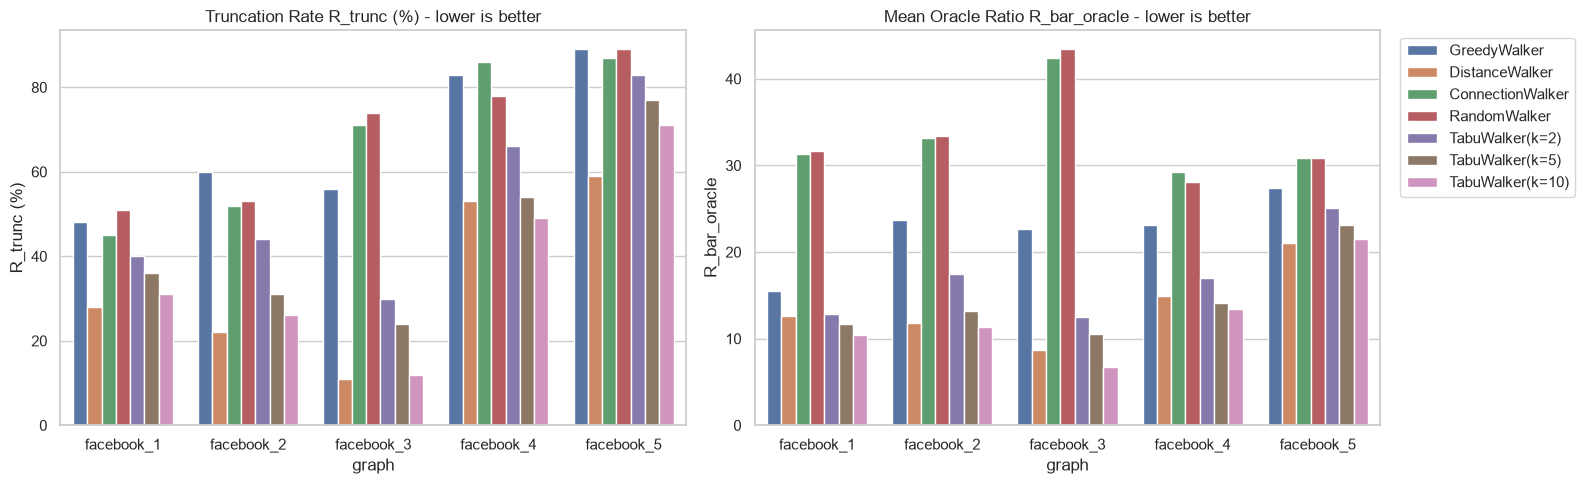

In [3]:
df_plot = df_results[df_results["model"] != "DijkstraOracle"]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.barplot(data=df_plot, x="graph", y="r_trunc", hue="model", ax=axes[0])
axes[0].set_title("Truncation Rate R_trunc (%) - lower is better")
axes[0].set_ylabel("R_trunc (%)")

sns.barplot(data=df_plot, x="graph", y="mean_oracle_ratio", hue="model", ax=axes[1])
axes[1].set_title("Mean Oracle Ratio R_bar_oracle - lower is better")
axes[1].set_ylabel("R_bar_oracle")

axes[0].legend_.remove()
axes[1].legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 3. Preliminary Failure Analysis (Ping-Pong vs Community Trapping)

In [4]:
g_inspect = "facebook_1"
for mname in ["GreedyWalker", "TabuWalker(k=5)"]:
    recs = detailed_records[g_inspect][mname]
    failed = [r for r in recs if r["truncated"]]
    print(f"\n=== {mname} on {g_inspect}: {len(failed)}/{len(recs)} truncated episodes ===")
    for r in failed[:2]:
        print(
            f"  src={r['source']} -> tgt={r['target']} | sp={r['shortest_path_len']} "
            f"| revisit={r['revisit_rate']:.2f} | ping_pong={r['ping_pong_count']} | cycles={r['cycle_count']}"
        )
        print(f"  First 25 trajectory steps: {r['trajectory'][:25]}")


=== GreedyWalker on facebook_1: 48/100 truncated episodes ===
  src=85 -> tgt=55 | sp=5 | revisit=0.98 | ping_pong=99 | cycles=99
  First 25 trajectory steps: [85, 97, 85, 97, 85, 97, 85, 97, 85, 97, 85, 97, 85, 97, 85, 97, 85, 97, 85, 97, 85, 97, 85, 97, 85]
  src=55 -> tgt=8 | sp=3 | revisit=0.97 | ping_pong=98 | cycles=98
  First 25 trajectory steps: [55, 54, 143, 54, 143, 54, 143, 54, 143, 54, 143, 54, 143, 54, 143, 54, 143, 54, 143, 54, 143, 54, 143, 54, 143]

=== TabuWalker(k=5) on facebook_1: 36/100 truncated episodes ===
  src=85 -> tgt=55 | sp=5 | revisit=0.93 | ping_pong=0 | cycles=94
  First 25 trajectory steps: [85, 97, 140, 87, 67, 117, 46, 85, 97, 140, 87, 67, 117, 46, 85, 97, 140, 87, 67, 117, 46, 85, 97, 140, 87]
  src=55 -> tgt=8 | sp=3 | revisit=0.92 | ping_pong=0 | cycles=93
  First 25 trajectory steps: [55, 54, 143, 133, 51, 66, 93, 98, 54, 143, 133, 51, 66, 93, 98, 54, 143, 133, 51, 66, 93, 98, 54, 143, 133]
